Load cleaned data

      ↓
Separate BENIGN / DDoS

      ↓
Check distribution of features

      ↓
Statistical test 

      ↓
Calculate p-value

      ↓
Calculate effect size

      ↓
Correct for multiple testing

      ↓
Rank statistically important features

      ↓
Visualize top features

      ↓
Select candidate features for Notebook 04

# Notebook 03 — Statistical Feature Analysis

## Objective

To statistically evaluate whether network traffic features differ significantly
between BENIGN and DDoS traffic.

### Questions

1. Which features differ significantly between BENIGN and DDoS?
2. How strong are these differences?
3. Which features should be considered for further feature selection?

### Statistical approach

- Mann–Whitney U test
- p-value
- Effect size
- Multiple-testing correction using Benjamini–Hochberg FDR

The results will provide statistical evidence for feature selection
in the subsequent notebook.

In [2]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests

In [4]:
df = pd.read_csv("netguard_cleaned.csv")

print("Dataset shape:", df.shape)
print("\nClass distribution:")
print(df["Label"].value_counts())

Dataset shape: (223082, 79)

Class distribution:
Label
DDoS      128014
BENIGN     95068
Name: count, dtype: int64


In [5]:
features = df.select_dtypes(include=np.number).columns.tolist()

print("Number of numerical features:", len(features))
print(features)

Number of numerical features: 78
['Destination Port', 'Flow Duration', 'Total Fwd Packets', 'Total Backward Packets', 'Total Length of Fwd Packets', 'Total Length of Bwd Packets', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std', 'Bwd Packet Length Max', 'Bwd Packet Length Min', 'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'Fwd Header Length', 'Bwd Header Length', 'Fwd Packets/s', 'Bwd Packets/s', 'Min Packet Length', 'Max Packet Length', 'Packet Length Mean', 'Packet Length Std', 'Packet Length Variance', 'FIN Flag Count', 'SYN Flag Count', 'RST Flag Count', 'PSH Flag Count', 'ACK Flag Count', 'URG Flag Count', 

## Statistical Test

### Mann–Whitney U Test

The Mann–Whitney U test compares the distributions of two independent groups.

In this project:

- Group 1 = BENIGN traffic
- Group 2 = DDoS traffic

### Hypotheses

H0:
The distributions of the feature are the same for BENIGN and DDoS traffic.

H1:
The distributions are different.

### Decision rule

If p-value < 0.05:

Reject H0 and consider the feature statistically significant.

However, because we test many features, we will apply
Benjamini–Hochberg False Discovery Rate correction.

In [7]:
benign = df[df["Label"] == "BENIGN"]
ddos = df[df["Label"] == "DDoS"]

print("BENIGN samples:", len(benign))
print("DDoS samples  :", len(ddos))

BENIGN samples: 95068
DDoS samples  : 128014


In [8]:
statistical_results = []

for feature in features:

    benign_values = benign[feature].dropna()
    ddos_values = ddos[feature].dropna()

    statistic, p_value = mannwhitneyu(
        benign_values,
        ddos_values,
        alternative="two-sided"
    )

    statistical_results.append({
        "Feature": feature,
        "U_Statistic": statistic,
        "P_Value": p_value,
        "BENIGN_Median": benign_values.median(),
        "DDoS_Median": ddos_values.median()
    })

stats_df = pd.DataFrame(statistical_results)

stats_df.head()

,Feature,U_Statistic,P_Value,BENIGN_Median,DDoS_Median
0,Destination Port,7.677624e+09,0.0,443.0,80.0
1,Flow Duration,4.309552e+09,0.0,217393.5,1879121.5
2,Total Fwd Packets,3.592084e+09,0.0,2.0,4.0
3,Total Backward Packets,6.765216e+09,0.0,2.0,4.0
4,Total Length of Fwd Packets,8.360339e+09,0.0,70.0,26.0


In [9]:
# Benjamini–Hochberg FDR correction.
reject, adjusted_pvalues, _, _ = multipletests(
    stats_df["P_Value"],
    alpha=0.05,
    method="fdr_bh"
)

stats_df["Adjusted_P_Value"] = adjusted_pvalues
stats_df["Significant"] = reject

stats_df.head()

,Feature,U_Statistic,P_Value,BENIGN_Median,DDoS_Median,Adjusted_P_Value,Significant
0,Destination Port,7.677624e+09,0.0,443.0,80.0,0.0,True
1,Flow Duration,4.309552e+09,0.0,217393.5,1879121.5,0.0,True
2,Total Fwd Packets,3.592084e+09,0.0,2.0,4.0,0.0,True
3,Total Backward Packets,6.765216e+09,0.0,2.0,4.0,0.0,True
4,Total Length of Fwd Packets,8.360339e+09,0.0,70.0,26.0,0.0,True


In [10]:
# Calculate effect size
def rank_biserial_effect_size(u, n1, n2):
    return 1 - (2 * u) / (n1 * n2)

In [11]:
effect_sizes = []

n_benign = len(benign)
n_ddos = len(ddos)

for _, row in stats_df.iterrows():

    effect_size = rank_biserial_effect_size(
        row["U_Statistic"],
        n_benign,
        n_ddos
    )

    effect_sizes.append(effect_size)

stats_df["Effect_Size"] = effect_sizes

In [12]:
stats_df["Abs_Effect_Size"] = stats_df["Effect_Size"].abs()

In [13]:
significant_features = (
    stats_df[stats_df["Significant"] == True]
    .sort_values(
        by="Abs_Effect_Size",
        ascending=False
    )
)

significant_features[
    [
        "Feature",
        "BENIGN_Median",
        "DDoS_Median",
        "P_Value",
        "Adjusted_P_Value",
        "Effect_Size",
        "Abs_Effect_Size"
    ]
].head(20)

,Feature,BENIGN_Median,DDoS_Median,P_Value,Adjusted_P_Value,Effect_Size,Abs_Effect_Size
11,Bwd Packet Length Min,6.000000,0.000000e+00,0.0,0.0,-0.593208,0.593208
13,Bwd Packet Length Std,0.000000,2.189773e+03,0.0,0.0,0.509735,0.509735
22,Fwd IAT Std,0.000000,9.324904e+05,0.0,0.0,0.505436,0.505436
6,Fwd Packet Length Max,42.000000,2.000000e+01,0.0,0.0,-0.494844,0.494844
66,Init_Win_bytes_forward,229.000000,2.560000e+02,0.0,0.0,0.492431,0.492431
8,Fwd Packet Length Mean,38.770979,7.000000e+00,0.0,0.0,-0.490744,0.490744
53,Avg Fwd Segment Size,38.770979,7.000000e+00,0.0,0.0,-0.490744,0.490744
68,act_data_pkt_fwd,1.000000,3.000000e+00,0.0,0.0,0.474326,0.474326
23,Fwd IAT Max,4.000000,1.762990e+06,0.0,0.0,0.471454,0.471454
21,Fwd IAT Mean,4.000000,4.906255e+05,0.0,0.0,0.468183,0.468183


In [14]:
print(
    "Statistically significant features:",
    stats_df["Significant"].sum()
)

print(
    "Total numerical features:",
    len(features)
)

Statistically significant features: 68
Total numerical features: 78


In [16]:
percentage = (
    stats_df["Significant"].sum()
    / len(features)
) * 100

print(f"Percentage significant: {percentage:.2f}%")

Percentage significant: 87.18%


In [18]:
top_effect_features = (
    stats_df
    .sort_values("Abs_Effect_Size", ascending=False)
    .head(20)
)

top_effect_features[
    [
        "Feature",
        "Effect_Size",
        "P_Value",
        "Adjusted_P_Value"
    ]
]

,Feature,Effect_Size,P_Value,Adjusted_P_Value
11,Bwd Packet Length Min,-0.593208,0.0,0.0
13,Bwd Packet Length Std,0.509735,0.0,0.0
22,Fwd IAT Std,0.505436,0.0,0.0
6,Fwd Packet Length Max,-0.494844,0.0,0.0
66,Init_Win_bytes_forward,0.492431,0.0,0.0
8,Fwd Packet Length Mean,-0.490744,0.0,0.0
53,Avg Fwd Segment Size,-0.490744,0.0,0.0
68,act_data_pkt_fwd,0.474326,0.0,0.0
23,Fwd IAT Max,0.471454,0.0,0.0
21,Fwd IAT Mean,0.468183,0.0,0.0


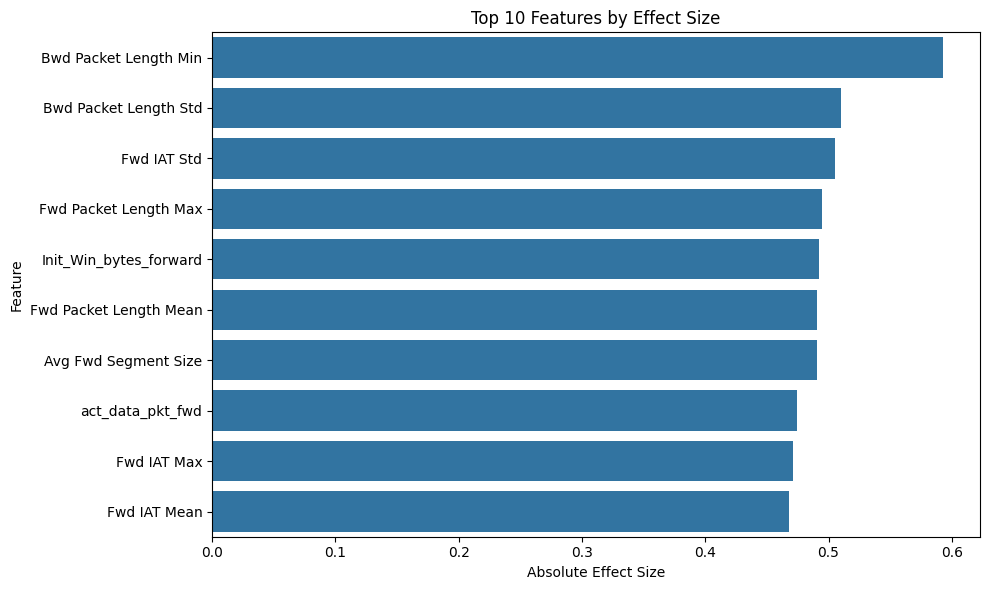

In [19]:
top_features = top_effect_features["Feature"].head(10).tolist()

plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_effect_features.head(10),
    x="Abs_Effect_Size",
    y="Feature"
)

plt.title("Top 10 Features by Effect Size")
plt.xlabel("Absolute Effect Size")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

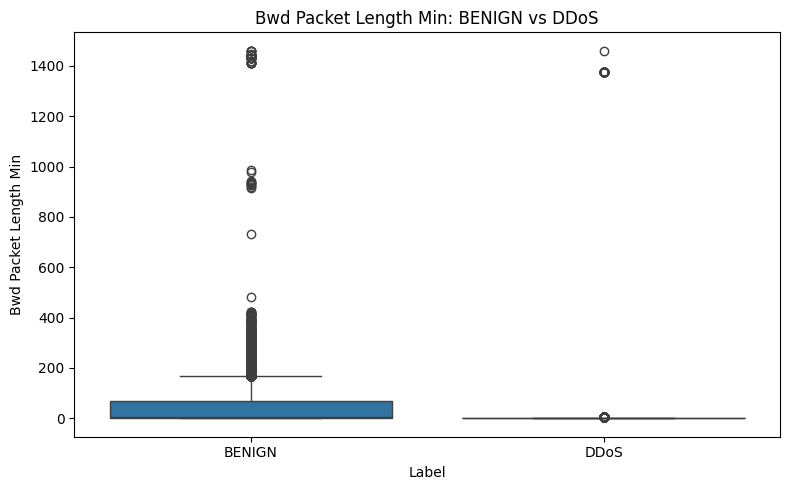

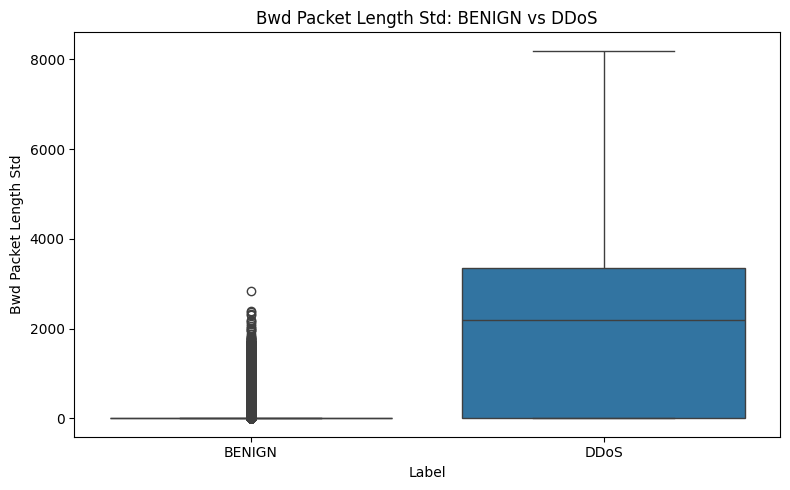

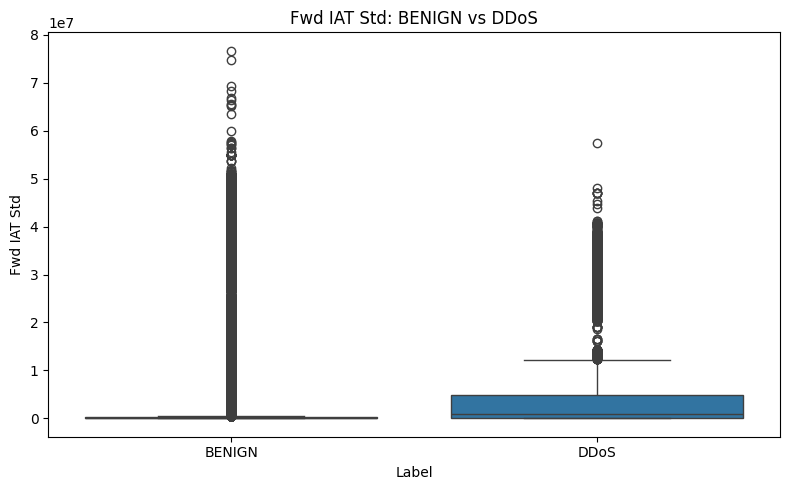

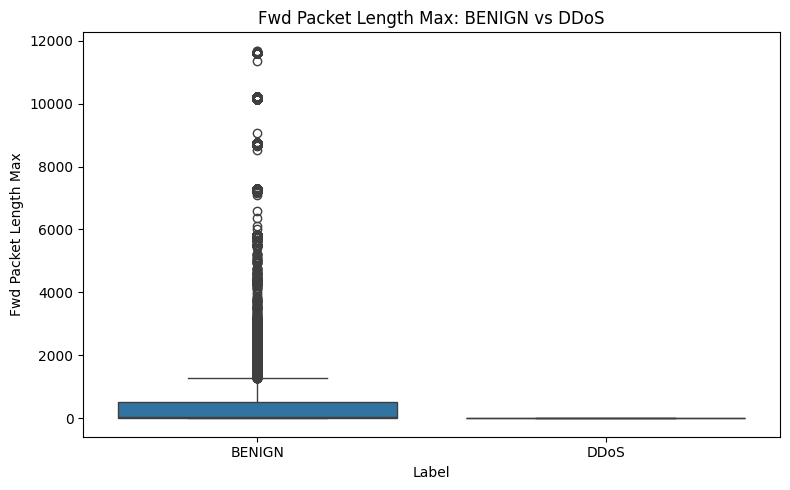

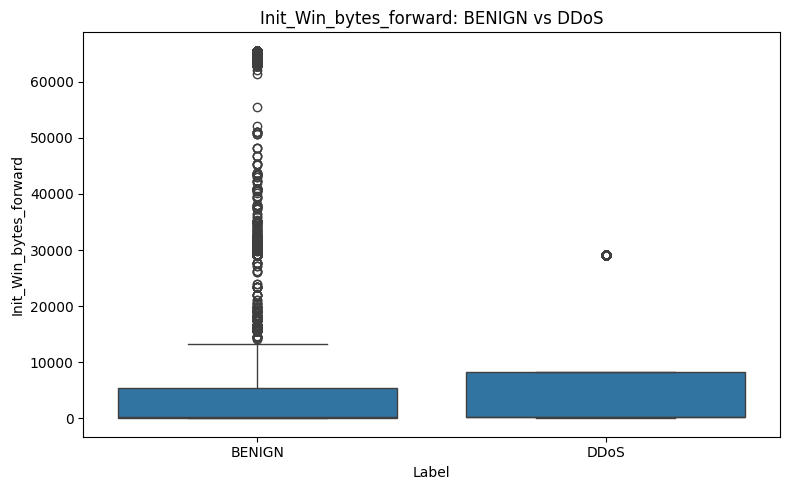

In [20]:
top_5_features = top_effect_features["Feature"].head(5).tolist()

for feature in top_5_features:

    plt.figure(figsize=(8, 5))

    sns.boxplot(
        data=df,
        x="Label",
        y=feature
    )

    plt.title(f"{feature}: BENIGN vs DDoS")
    plt.tight_layout()
    plt.show()

In [21]:
final_stats = stats_df[
    [
        "Feature",
        "BENIGN_Median",
        "DDoS_Median",
        "P_Value",
        "Adjusted_P_Value",
        "Effect_Size",
        "Abs_Effect_Size",
        "Significant"
    ]
].sort_values(
    by="Abs_Effect_Size",
    ascending=False
)

final_stats.head(20)

,Feature,BENIGN_Median,DDoS_Median,P_Value,Adjusted_P_Value,Effect_Size,Abs_Effect_Size,Significant
11,Bwd Packet Length Min,6.000000,0.000000e+00,0.0,0.0,-0.593208,0.593208,True
13,Bwd Packet Length Std,0.000000,2.189773e+03,0.0,0.0,0.509735,0.509735,True
22,Fwd IAT Std,0.000000,9.324904e+05,0.0,0.0,0.505436,0.505436,True
6,Fwd Packet Length Max,42.000000,2.000000e+01,0.0,0.0,-0.494844,0.494844,True
66,Init_Win_bytes_forward,229.000000,2.560000e+02,0.0,0.0,0.492431,0.492431,True
8,Fwd Packet Length Mean,38.770979,7.000000e+00,0.0,0.0,-0.490744,0.490744,True
53,Avg Fwd Segment Size,38.770979,7.000000e+00,0.0,0.0,-0.490744,0.490744,True
68,act_data_pkt_fwd,1.000000,3.000000e+00,0.0,0.0,0.474326,0.474326,True
23,Fwd IAT Max,4.000000,1.762990e+06,0.0,0.0,0.471454,0.471454,True
21,Fwd IAT Mean,4.000000,4.906255e+05,0.0,0.0,0.468183,0.468183,True


In [22]:
final_stats.to_csv(
    "statistical_feature_analysis.csv",
    index=False
)

print("Statistical results saved.")

Statistical results saved.


# Conclusion

The Mann–Whitney U test was used to compare network-flow feature
distributions between BENIGN and DDoS traffic.

The p-values were adjusted using the Benjamini–Hochberg
False Discovery Rate procedure to account for multiple comparisons.

Effect sizes were calculated to measure the magnitude of the
difference between the two traffic classes.

Features with statistically significant differences and meaningful
effect sizes were identified as candidate features for the next
feature-selection stage.

Important:

Statistical significance alone does not mean that a feature is
the best feature for machine learning. Feature redundancy,
multicollinearity, model performance, and feature importance will
also be considered in the next stage.